# **Giai đoạn 1: Thu thập và đánh giá dữ liệu ban đầu.**

◦ **Nguồn dữ liệu:** Nêu rõ tập dữ liệu đã lựa chọn, cấu trúc các file, thuộc tính, số lượng quan sát và mục tiêu bài toán.

◦ **Kiểm tra hiện trạng**:Rà soát cấu trúc, kiểu dữ liệu từng trường, tỷ lệ giá trị khuyết thiếu (missing values), tính nhất quán giữa các file dữ liệu (nếu gộp bảng qua khóa chính/khóa ngoại)

In [179]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [180]:
import pandas as pd
import numpy as np

In [181]:
thu_muc = "/content/drive/MyDrive/Colab Notebooks/Data"   # thư mục chứa 3 file csv

# Nhập dữ liệu từ 3 file csv (chứng minh nguồn dữ liệu và cách nạp vào DataFrame)
clean = pd.read_csv(thu_muc + "/Clean_Dataset.csv")
eco = pd.read_csv(thu_muc + "/economy.csv")
biz = pd.read_csv(thu_muc + "/business.csv")

# Rà soát cấu trúc: số dòng, số cột của từng file
print("economy.csv       :", eco.shape)
print("business.csv      :", biz.shape)
print("Clean_Dataset.csv :", clean.shape)

# Rà soát cấu trúc: tên các cột (thuộc tính) của file thô và file Clean
print("Cột file thô:", list(eco.columns))
print("Cột file Clean:", list(clean.columns))

economy.csv       : (206774, 11)
business.csv      : (93487, 11)
Clean_Dataset.csv : (300153, 12)
Cột file thô: ['date', 'airline', 'ch_code', 'num_code', 'dep_time', 'from', 'time_taken', 'stop', 'arr_time', 'to', 'price']
Cột file Clean: ['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class', 'duration', 'days_left', 'price']


***Nhận xét***: Hai file thô cùng 11 cột, nên có thể nối theo chiều dọc. Bản Clean có thêm cột chỉ số Unnamed: 0 và cột class.

In [182]:
# Rà soát cấu trúc bảng Clean_Dataset: số dòng, số cột, kiểu dữ liệu, số giá trị không thiếu
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [183]:
# Rà soát cấu trúc bảng economy: số dòng, số cột, kiểu dữ liệu, số giá trị không thiếu
eco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206774 entries, 0 to 206773
Data columns (total 11 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   date        206774 non-null  object
 1   airline     206774 non-null  object
 2   ch_code     206774 non-null  object
 3   num_code    206774 non-null  int64 
 4   dep_time    206774 non-null  object
 5   from        206774 non-null  object
 6   time_taken  206774 non-null  object
 7   stop        206774 non-null  object
 8   arr_time    206774 non-null  object
 9   to          206774 non-null  object
 10  price       206774 non-null  object
dtypes: int64(1), object(10)
memory usage: 17.4+ MB


In [184]:
# Rà soát cấu trúc bảng business: số dòng, số cột, kiểu dữ liệu, số giá trị không thiếu
biz.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93487 entries, 0 to 93486
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        93487 non-null  object
 1   airline     93487 non-null  object
 2   ch_code     93487 non-null  object
 3   num_code    93487 non-null  int64 
 4   dep_time    93487 non-null  object
 5   from        93487 non-null  object
 6   time_taken  93487 non-null  object
 7   stop        93487 non-null  object
 8   arr_time    93487 non-null  object
 9   to          93487 non-null  object
 10  price       93487 non-null  object
dtypes: int64(1), object(10)
memory usage: 7.8+ MB


In [185]:
# Rà soát cấu trúc: số tuyến bay và các thành phố (chứng minh phạm vi dữ liệu: 6 thành phố, 30 tuyến)
tuyen = clean["source_city"] + "-" + clean["destination_city"]
print("Số tuyến bay trong Clean:", len(np.unique(tuyen)))
print("Các thành phố:", np.unique(clean["source_city"]))

Số tuyến bay trong Clean: 30
Các thành phố: ['Bangalore' 'Chennai' 'Delhi' 'Hyderabad' 'Kolkata' 'Mumbai']


***- Kiểu dữ liệu từng trường và tỷ lệ giá trị khuyết thiếu (missing values):***

In [186]:
# Kiểm tra kiểu dữ liệu từng trường + tỷ lệ missing + số giá trị khác nhau (bản Clean)
so_khac_nhau = pd.Series([len(np.unique(clean[c])) for c in clean.columns],
                         index=clean.columns)
kiem_tra = pd.DataFrame({
    "kieu": clean.dtypes,
    "missing": clean.isna().sum(),
    "ti_le_%": ((clean.isna().sum() / len(clean)) * 100).round(2),
    "so_gia_tri": so_khac_nhau
})
print(kiem_tra)
print("Tổng số ô thiếu:", clean.isna().sum().sum())

                     kieu  missing  ti_le_%  so_gia_tri
Unnamed: 0          int64        0      0.0      300153
airline            object        0      0.0           6
flight             object        0      0.0        1561
source_city        object        0      0.0           6
departure_time     object        0      0.0           6
stops              object        0      0.0           3
arrival_time       object        0      0.0           6
destination_city   object        0      0.0           6
class              object        0      0.0           2
duration          float64        0      0.0         476
days_left           int64        0      0.0          49
price               int64        0      0.0       12157
Tổng số ô thiếu: 0


***Nhận xét:***  kiểu dữ liệu phù hợp (số thực cho duration, số nguyên cho days_left và price, chuỗi cho các biến phân loại). Không có giá trị khuyết thiếu ở bất kỳ cột nào (tỷ lệ 0%), nên không cần bước điền giá trị thiếu. Cột stops chỉ có 3 giá trị khác nhau và class có 2, đúng với các nhóm đã mô tả.

In [187]:
# Kiểm tra dòng trùng lặp ở bản Clean (bỏ cột chỉ số vì nó luôn khác nhau giữa các dòng)
clean_khong_chi_so = clean.copy()
del clean_khong_chi_so["Unnamed: 0"]
print("Số dòng trùng lặp:", clean_khong_chi_so.duplicated().sum())

Số dòng trùng lặp: 0


In [188]:
# Gộp hai file thô thành một bảng để kiểm tra chung (thêm cột class để phân biệt hạng vé)
eco["class"] = "Economy"
biz["class"] = "Business"
raw = pd.concat([eco, biz])

In [189]:
# Kiểm tra kiểu dữ liệu bất thường: price ở file thô là chuỗi có dấu phẩy, không phải số
print("Ví dụ:", eco.loc[0, "price"], "| kiểu:", raw["price"].dtype)
print("Số dòng price có dấu phẩy:", raw["price"].str.contains(",").sum())

Ví dụ: 5,953 | kiểu: object
Số dòng price có dấu phẩy: 300261


***Nhận xét:*** toàn bộ 300.261 dòng của price ở file thô là chuỗi có dấu phẩy ngăn cách nghìn, phải chuyển sang số trước khi tính toán. Bản Clean đã chuyển sẵn thành số nguyên.

In [190]:
# Kiểm tra định dạng bất thường ở time_taken: định dạng đúng "02h 10m", dạng sai có dấu chấm
print(raw["time_taken"].str.len().value_counts())
sai_dinh_dang = raw[raw["time_taken"].str.contains(r"\.", regex=True)]
print("Số dòng time_taken sai định dạng:", len(sai_dinh_dang))
print(sai_dinh_dang[["date", "airline", "from", "to", "time_taken", "price"]])

time_taken
7    300220
6        41
Name: count, dtype: int64
Số dòng time_taken sai định dạng: 4
              date   airline       from         to time_taken  price
96486   26-02-2022  GO FIRST  Bangalore     Mumbai    1.03h m  5,177
104676  26-02-2022  GO FIRST  Bangalore    Kolkata    1.02h m  5,177
111315  26-02-2022  GO FIRST  Bangalore  Hyderabad    1.03h m  4,337
154007  25-02-2022  GO FIRST  Hyderabad      Delhi    1.01h m  6,132


***Nhận xét:*** có 4 dòng của hãng GO FIRST bị sai định dạng thời lượng (1.03h m thay vì 01h 03m). Con số 6 ký tự ở 41 dòng là dạng hợp lệ 2h 10m (giờ có một chữ số), không phải lỗi.

In [191]:
# Kiểm tra ký tự thừa ở cột stop: có xuống dòng, tab và tên điểm dừng
print("Ví dụ giá trị gốc:", repr(biz.loc[2, "stop"]))
print("Số dòng chứa ký tự xuống dòng:", raw["stop"].str.contains("\n").sum())
print("Số dòng có khoảng trắng/ký tự thừa ở đầu hoặc cuối:",
      (raw["stop"] != raw["stop"].str.strip()).sum())
print("Số dòng có tên điểm dừng (chứa 'Via'):", raw["stop"].str.contains("Via").sum())

Ví dụ giá trị gốc: '1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t'
Số dòng chứa ký tự xuống dòng: 250929
Số dòng có khoảng trắng/ký tự thừa ở đầu hoặc cuối: 286973
Số dòng có tên điểm dừng (chứa 'Via'): 7326


In [192]:
# Quy cột stop về 3 nhóm sau khi bỏ ký tự thừa (strip), để khớp biến stops của bản Clean
stop_sach = raw["stop"].str.strip()
print("non-stop:", stop_sach.str.startswith("non-stop").sum())
print("1-stop  :", stop_sach.str.startswith("1-stop").sum())
print("2+-stop :", stop_sach.str.startswith("2+-stop").sum())

non-stop: 36044
1-stop  : 250929
2+-stop : 13288


***Nhận xét:*** cột stop ở file thô lẫn ký tự xuống dòng, tab và tên điểm dừng (7.326 dòng), nên không đếm trực tiếp được. Sau khi strip và nhóm theo phần đầu chuỗi, ba nhóm cộng lại đúng 300.261 dòng, không sót dòng nào.

***Kết luận:***

- Dữ liệu thô và bản Clean đều không có giá trị khuyết thiếu (0%).
- Bản Clean có kiểu dữ liệu phù hợp và không có dòng trùng lặp.
- File thô có các lỗi định dạng (không phải missing): price là chuỗi, 4 dòng time_taken sai, cột stop lẫn ký tự thừa.



***- Tính nhất quán giữa các file dữ liệu***

In [193]:
# Đối chiếu tổng số dòng: thô (economy + business) so với Clean
print("Thô:", len(raw), "| Clean:", len(clean), "| Chênh:", len(raw) - len(clean))

Thô: 300261 | Clean: 300153 | Chênh: 108


In [194]:
# Đối chiếu số dòng theo từng hãng để xác định chênh lệch nằm ở đâu
so_tho = raw["airline"].str.replace(" ", "_").value_counts()
so_clean = clean["airline"].value_counts()
so_tho.name = "tho"
so_clean.name = "clean"
bang_hang = pd.concat([so_tho, so_clean], axis=1).fillna(0).astype(int)
bang_hang["chenh"] = bang_hang["tho"] - bang_hang["clean"]
print(bang_hang)

              tho   clean  chenh
airline                         
Vistara    127859  127859      0
Air_India   80894   80892      2
Indigo      43120   43120      0
GO_FIRST    23177   23173      4
AirAsia     16098   16098      0
SpiceJet     9011    9011      0
StarAir        61       0     61
Trujet         41       0     41


In [195]:
# Kiểm tra dòng trùng lặp ở file thô
print("Số dòng trùng:", raw.duplicated().sum())
print(raw[raw.duplicated()][["date", "airline", "ch_code", "num_code",
                             "dep_time", "from", "to", "price"]])

Số dòng trùng: 2
            date    airline ch_code  num_code dep_time   from      to   price
563   14-02-2022  Air India      AI       807    17:20  Delhi  Mumbai  12,150
6181  13-03-2022  Air India      AI       475    13:00  Delhi  Mumbai   4,780


In [196]:
# Tái hiện lại các bước làm sạch để chứng minh 108 dòng chênh lệch giải thích được hoàn toàn
n0 = len(raw)
b1 = raw[(raw["airline"] != "StarAir") & (raw["airline"] != "Trujet")]   # loại 2 hãng quá ít dòng
n1 = len(b1)
b2 = b1.drop_duplicates()                                                # loại dòng trùng lặp
n2 = len(b2)
b3 = b2[~b2["time_taken"].str.contains(r"\.", regex=True)]               # loại time_taken sai định dạng
n3 = len(b3)
print("Ban đầu:", n0, "| Loại StarAir, Trujet: -", n0 - n1, "->", n1)
print("Loại trùng: -", n1 - n2, "->", n2, "| Loại sai định dạng: -", n2 - n3, "->", n3)
print("Số dòng Clean:", len(clean), "| Khớp:", n3 == len(clean))

Ban đầu: 300261 | Loại StarAir, Trujet: - 102 -> 300159
Loại trùng: - 2 -> 300157 | Loại sai định dạng: - 4 -> 300153
Số dòng Clean: 300153 | Khớp: True


***Nhận xét:*** chênh lệch 108 dòng giữa file thô và Clean giải thích được hoàn toàn bởi 3 nguyên nhân: 61 dòng StarAir cộng 41 dòng Trujet (hai hãng quá ít quan sát), 2 dòng trùng của Air India, và 4 dòng GO FIRST có time_taken sai định dạng. Ba file nhất quán với nhau, và bản Clean đáng tin cậy để dùng cho phân tích.

In [197]:
# Kiểm tra quan hệ giữa ngày bay (file thô) và days_left (Clean)
ngay_bay = pd.to_datetime(raw["date"], format="%d-%m-%Y")
print("Ngày bay:", ngay_bay.min().date(), "->", ngay_bay.max().date())
print("Số ngày bay khác nhau:", len(np.unique(ngay_bay)),
      "| Số giá trị days_left khác nhau:", len(np.unique(clean["days_left"])))

Ngày bay: 2022-02-11 -> 2022-03-31
Số ngày bay khác nhau: 49 | Số giá trị days_left khác nhau: 49


# **Giai đoạn 2: Tiền xử lý và làm sạch dữ liệu**

◦ **Xử lý bất thường:** Đưa ra minh chứng rõ ràng những vấn đề về sai định dạng, dữ liệu trùng lặp hay ngoại lệ (outliers) (nếu có). Minh chứng có thể là các biểu đồ hoặc một phương pháp tính toán nào đó.

◦ **Giải trình lựa chọn kỹ thuật:** Không chỉ trình bày code, nhóm cần nêu lý do chọn giải pháp.

Đối với bộ dữ liệu business.csv

In [198]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [199]:
import pandas as pd
import os

file_path = '/content/drive/MyDrive/Colab Notebooks/Data/business.csv'

# Kiểm tra tệp tin có tồn tại hay không trước khi đọc
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print("Đọc dữ liệu thành công!")
    df.info()
else:
    print(f"Lỗi: Không tìm thấy tệp tin tại đường dẫn: {file_path}")
    print("Vui lòng đảm bảo bạn đã kết nối Google Drive và đường dẫn hoàn toàn chính xác.")

Đọc dữ liệu thành công!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93487 entries, 0 to 93486
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        93487 non-null  object
 1   airline     93487 non-null  object
 2   ch_code     93487 non-null  object
 3   num_code    93487 non-null  int64 
 4   dep_time    93487 non-null  object
 5   from        93487 non-null  object
 6   time_taken  93487 non-null  object
 7   stop        93487 non-null  object
 8   arr_time    93487 non-null  object
 9   to          93487 non-null  object
 10  price       93487 non-null  object
dtypes: int64(1), object(10)
memory usage: 7.8+ MB


In [200]:
import numpy as np
import pandas as pd
path = "/content/drive/MyDrive/Colab Notebooks/Data/business.csv"
df = pd.read_csv(path)
df.head()

,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,Air India,AI,868,18:00,Delhi,02h 00m,non-stop,20:00,Mumbai,"25,612"
1,11-02-2022,Air India,AI,624,19:00,Delhi,02h 15m,non-stop,21:15,Mumbai,"25,612"
2,11-02-2022,Air India,AI,531,20:00,Delhi,24h 45m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t,20:45,Mumbai,"42,220"
3,11-02-2022,Air India,AI,839,21:25,Delhi,26h 30m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t,23:55,Mumbai,"44,450"
4,11-02-2022,Air India,AI,544,17:15,Delhi,06h 40m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t,23:55,Mumbai,"46,690"


In [201]:
# Kiểm tra giá trị thiếu trong từng cột
print(df.isnull().sum())

# Kiểm tra tổng số giá trị thiếu
print("Tổng số giá trị thiếu:", df.isnull().sum().sum())

date          0
airline       0
ch_code       0
num_code      0
dep_time      0
from          0
time_taken    0
stop          0
arr_time      0
to            0
price         0
dtype: int64
Tổng số giá trị thiếu: 0


In [202]:
missing_values = ["", " ", "NA", "N/A", "-", "null", "None"]

for col in df.columns:
    count = df[col].astype(str).str.strip().isin(missing_values).sum()
    print(f"{col}: {count}")

date: 0
airline: 0
ch_code: 0
num_code: 0
dep_time: 0
from: 0
time_taken: 0
stop: 0
arr_time: 0
to: 0
price: 0


In [203]:
# Chuyển các khoảng trắng liên tiếp thành một dấu cách
df["stop"] = df["stop"].astype(str).apply(
    lambda x: re.sub(r"\s+", " ", x).strip()
)

# Kiểm tra kết quả
print(df["stop"].value_counts().head(20))

stop
1-stop                    81489
non-stop                   8102
2+-stop                    1083
1-stop Via IDR              810
1-stop Via IXU              776
1-stop Via PAT              257
1-stop Via Patna            242
1-stop Via BBI              152
1-stop Via STV               93
1-stop Via IXE               86
1-stop Via Bhubaneswar       75
1-stop Via Hyderabad         71
1-stop Via Delhi             59
1-stop Via Raipur            43
1-stop Via Chennai           42
1-stop Via Guwahati          29
1-stop Via VTZ               17
1-stop Via Kolkata           14
1-stop Via NDC               14
1-stop Via RPR               13
Name: count, dtype: int64


In [204]:
# Tách số điểm dừng
df["stops"] = df["stop"].str.extract(
    r"^(non-stop|1-stop|2\+-stop)"
)

# Tách thành phố trung chuyển
df["via_city"] = df["stop"].str.extract(
    r"Via\s+(.+)"
)

# Chuyển số điểm dừng thành dạng số
stop_mapping = {
    "non-stop": 0,
    "1-stop": 1,
    "2+-stop": 2
}

df["stops"] = df["stops"].map(stop_mapping)

# Kiểm tra kết quả
print(df[["stop", "stops", "via_city"]].head(15))

        stop  stops via_city
0   non-stop      0      NaN
1   non-stop      0      NaN
2     1-stop      1      NaN
3     1-stop      1      NaN
4     1-stop      1      NaN
5   non-stop      0      NaN
6     1-stop      1      NaN
7     1-stop      1      NaN
8     1-stop      1      NaN
9   non-stop      0      NaN
10    1-stop      1      NaN
11    1-stop      1      NaN
12    1-stop      1      NaN
13    1-stop      1      NaN
14    1-stop      1      NaN


In [205]:
city_mapping = {
    "IDR": "Indore",
    "IXU": "Aurangabad",
    "STV": "Surat",
    "GAY": "Gaya",
    "GAU": "Guwahati",
    "VTZ": "Visakhapatnam",
    "NDC": "Nanded",
    "IXE": "Mangalore",
    "PAT": "Patna",
    "RPR": "Raipur",
    "HYD": "Hyderabad",
    "BBI": "Bhubaneswar"
}

df["via_city"] = df["via_city"].replace(city_mapping)

# Xử lý giá trị không có thành phố trung chuyển
df.loc[df["stops"] == 0, "via_city"] = "Not applicable"

# Những chuyến có điểm dừng nhưng không có thông tin thành phố
df.loc[
    (df["stops"] > 0) & (df["via_city"].isna()),
    "via_city"
] = "Unknown"

# Kiểm tra kết quả
print(df["via_city"].value_counts(dropna=False))

via_city
Unknown           82572
Not applicable     8102
Indore              810
Aurangabad          776
Patna               499
Bhubaneswar         227
Surat                96
Mangalore            86
Hyderabad            72
Delhi                59
Raipur               56
Chennai              42
Guwahati             32
Visakhapatnam        17
Nanded               14
Kolkata              14
Lucknow              10
Gaya                  3
Name: count, dtype: int64


In [206]:
# Xóa dấu phẩy trong giá vé
df["price"] = df["price"].astype(str).str.replace(",", "", regex=False)

# Chuyển sang kiểu số nguyên
df["price"] = df["price"].astype(int)

# Kiểm tra
print(df["price"].dtype)
print(df["price"].head())

int64
0    25612
1    25612
2    42220
3    44450
4    46690
Name: price, dtype: int64


In [207]:
# Chuyển sang định dạng ngày tháng
df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%Y"
)

# Kiểm tra
print(df["date"].dtype)
print(df["date"].head())

datetime64[ns]
0   2022-02-11
1   2022-02-11
2   2022-02-11
3   2022-02-11
4   2022-02-11
Name: date, dtype: datetime64[ns]


In [208]:
print(df["time_taken"].head())
print(df["time_taken"].dtype)

0    02h 00m
1    02h 15m
2    24h 45m
3    26h 30m
4    06h 40m
Name: time_taken, dtype: object
object


In [209]:
# Kiểm tra thời gian bay sau khi chuyển đổi
print(df["time_taken"].head())
print(df["time_taken"].head())

0    02h 00m
1    02h 15m
2    24h 45m
3    26h 30m
4    06h 40m
Name: time_taken, dtype: object
0    02h 00m
1    02h 15m
2    24h 45m
3    26h 30m
4    06h 40m
Name: time_taken, dtype: object


In [210]:
# Chỉ lấy phần giờ và phút
df["dep_time"] = df["dep_time"].astype(str).str.extract(r"(\d{2}:\d{2})")[0]
df["arr_time"] = df["arr_time"].astype(str).str.extract(r"(\d{2}:\d{2})")[0]

# Chuyển sang định dạng thời gian
df["dep_time"] = pd.to_datetime(df["dep_time"], format="%H:%M").dt.time
df["arr_time"] = pd.to_datetime(df["arr_time"], format="%H:%M").dt.time

# Kiểm tra kết quả
print(df[["dep_time", "arr_time"]].head())

   dep_time  arr_time
0  18:00:00  20:00:00
1  19:00:00  21:15:00
2  20:00:00  20:45:00
3  21:25:00  23:55:00
4  17:15:00  23:55:00


In [211]:
# Đếm số dòng trùng lặp hoàn toàn
print("Số dòng trùng lặp:", df.duplicated().sum())

Số dòng trùng lặp: 0


In [212]:
df = df.drop_duplicates()

In [213]:
# Các cột dùng để xác định cùng một chuyến bay
flight_columns = [
    "date", "airline", "num_code",
    "dep_time", "from", "time_taken",
    "stops", "arr_time", "to"
]

# Tìm các nhóm có thông tin chuyến bay giống nhau
duplicate_flights = df[
    df.duplicated(subset=flight_columns, keep=False)
].sort_values(flight_columns)

# Hiển thị kết quả
print("Số bản ghi thuộc các nhóm có cùng thông tin chuyến bay:",
      len(duplicate_flights))

duplicate_flights.head(10)

Số bản ghi thuộc các nhóm có cùng thông tin chuyến bay: 640


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price,stops,via_city
9192,2022-02-11,Vistara,UK,809,19:50:00,Delhi,21h 05m,2+-stop,16:55:00,Kolkata,114434,2,Unknown
9193,2022-02-11,Vistara,UK,809,19:50:00,Delhi,21h 05m,2+-stop,16:55:00,Kolkata,116562,2,Unknown
76366,2022-02-12,Vistara,UK,830,10:20:00,Hyderabad,23h 15m,1-stop,09:35:00,Kolkata,68474,1,Unknown
76374,2022-02-12,Vistara,UK,830,10:20:00,Hyderabad,23h 15m,1-stop,09:35:00,Kolkata,80950,1,Unknown
89285,2022-02-12,Vistara,UK,838,21:05:00,Chennai,23h 40m,2+-stop,20:45:00,Kolkata,68963,2,Unknown
89293,2022-02-12,Vistara,UK,838,21:05:00,Chennai,23h 40m,2+-stop,20:45:00,Kolkata,71169,2,Unknown
76367,2022-02-12,Vistara,UK,860,06:50:00,Hyderabad,26h 45m,1-stop,09:35:00,Kolkata,68474,1,Unknown
76375,2022-02-12,Vistara,UK,860,06:50:00,Hyderabad,26h 45m,1-stop,09:35:00,Kolkata,80950,1,Unknown
76350,2022-02-12,Vistara,UK,880,13:25:00,Hyderabad,31h 20m,2+-stop,20:45:00,Kolkata,56669,2,Unknown
76362,2022-02-12,Vistara,UK,880,13:25:00,Hyderabad,31h 20m,2+-stop,20:45:00,Kolkata,64733,2,Unknown


In [214]:
import re

def convert_time_to_minutes(val):
    if pd.isna(val):
        return None
    match = re.findall(r'(\d+)', str(val))
    if len(match) == 2:
        return int(match[0]) * 60 + int(match[1])
    elif len(match) == 1:
        return int(match[0]) * 60 # Trường hợp chỉ có giờ
    return 0

# Tạo bản sao và chuyển đổi time_taken sang số phút để kiểm tra ngoại lệ
df_temp = df.copy()
df_temp['time_taken_minutes'] = df_temp['time_taken'].apply(convert_time_to_minutes)

def check_outliers_numeric(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    print(f"\nCột: {column}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Ngưỡng dưới:", lower_bound)
    print("Ngưỡng trên:", upper_bound)
    print("Số lượng ngoại lệ:", len(outliers))
    print("Tỷ lệ ngoại lệ:", round(len(outliers) / len(data) * 100, 2), "%")

# Kiểm tra ngoại lệ cho price và time_taken (đã quy đổi ra phút)
check_outliers_numeric(df, "price")
check_outliers_numeric(df_temp, "time_taken_minutes")


Cột: price
Q1: 45185.0
Q3: 60396.0
IQR: 15211.0
Ngưỡng dưới: 22368.5
Ngưỡng trên: 83212.5
Số lượng ngoại lệ: 3650
Tỷ lệ ngoại lệ: 3.9 %

Cột: time_taken_minutes
Q1: 530.0
Q3: 1070.0
IQR: 540.0
Ngưỡng dưới: -280.0
Ngưỡng trên: 1880.0
Số lượng ngoại lệ: 90
Tỷ lệ ngoại lệ: 0.1 %


In [215]:
# Kiểm tra kích thước dữ liệu sau khi làm sạch
print("Kích thước dữ liệu sau khi làm sạch:", df.shape)

# Kiểm tra kiểu dữ liệu
print(df.dtypes)

# Kiểm tra giá trị thiếu
print("\nGiá trị thiếu trong từng cột:")
print(df.isnull().sum())

# Hiển thị 5 dòng dữ liệu sau khi làm sạch
df.head()

Kích thước dữ liệu sau khi làm sạch: (93487, 13)
date          datetime64[ns]
airline               object
ch_code               object
num_code               int64
dep_time              object
from                  object
time_taken            object
stop                  object
arr_time              object
to                    object
price                  int64
stops                  int64
via_city              object
dtype: object

Giá trị thiếu trong từng cột:
date          0
airline       0
ch_code       0
num_code      0
dep_time      0
from          0
time_taken    0
stop          0
arr_time      0
to            0
price         0
stops         0
via_city      0
dtype: int64


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price,stops,via_city
0,2022-02-11,Air India,AI,868,18:00:00,Delhi,02h 00m,non-stop,20:00:00,Mumbai,25612,0,Not applicable
1,2022-02-11,Air India,AI,624,19:00:00,Delhi,02h 15m,non-stop,21:15:00,Mumbai,25612,0,Not applicable
2,2022-02-11,Air India,AI,531,20:00:00,Delhi,24h 45m,1-stop,20:45:00,Mumbai,42220,1,Unknown
3,2022-02-11,Air India,AI,839,21:25:00,Delhi,26h 30m,1-stop,23:55:00,Mumbai,44450,1,Unknown
4,2022-02-11,Air India,AI,544,17:15:00,Delhi,06h 40m,1-stop,23:55:00,Mumbai,46690,1,Unknown


In [216]:
# Xuất dữ liệu đã làm sạch
df.to_csv("business_cleaned.csv", index=False)

print("Đã lưu dữ liệu thành công!")

Đã lưu dữ liệu thành công!


In [217]:
# Lưu các bản ghi cần kiểm tra vào file CSV
duplicate_flights.to_csv(
    "duplicate_flights_check.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Đã xuất file duplicate_flights_check.csv thành công!")

Đã xuất file duplicate_flights_check.csv thành công!


**Đối với dữ liệu economy.cvs**

In [218]:
# Kết nối Google Drive
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [219]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [220]:
file_path2 = '/content/drive/MyDrive/Colab Notebooks/Data/economy.csv'

In [221]:
# Kiểm tra file có tồn tại không
if os.path.exists(file_path2):
    df = pd.read_csv(file_path2)
    print("Đọc dữ liệu thành công!")
    df.info()
else:
    print(f"Lỗi: Không tìm thấy tệp tin tại đường dẫn: {file_path2}")
    print("Vui lòng đảm bảo bạn đã kết nối Google Drive và đường dẫn hoàn toàn chính xác.")

Đọc dữ liệu thành công!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206774 entries, 0 to 206773
Data columns (total 11 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   date        206774 non-null  object
 1   airline     206774 non-null  object
 2   ch_code     206774 non-null  object
 3   num_code    206774 non-null  int64 
 4   dep_time    206774 non-null  object
 5   from        206774 non-null  object
 6   time_taken  206774 non-null  object
 7   stop        206774 non-null  object
 8   arr_time    206774 non-null  object
 9   to          206774 non-null  object
 10  price       206774 non-null  object
dtypes: int64(1), object(10)
memory usage: 17.4+ MB


In [222]:
path2 = "/content/drive/MyDrive/Colab Notebooks/Data/economy.csv"
df = pd.read_csv(path2)
df.head()

,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,SpiceJet,SG,8709,18:55,Delhi,02h 10m,non-stop,21:05,Mumbai,"5,953"
1,11-02-2022,SpiceJet,SG,8157,06:20,Delhi,02h 20m,non-stop,08:40,Mumbai,"5,953"
2,11-02-2022,AirAsia,I5,764,04:25,Delhi,02h 10m,non-stop,06:35,Mumbai,"5,956"
3,11-02-2022,Vistara,UK,995,10:20,Delhi,02h 15m,non-stop,12:35,Mumbai,"5,955"
4,11-02-2022,Vistara,UK,963,08:50,Delhi,02h 20m,non-stop,11:10,Mumbai,"5,955"


In [223]:
#Tạo một bản sao dữ liệu gốc để có thể đối chiếu trước và sau khi làm sạch
df_kiemtra = df.copy()

print("Kích thước dữ liệu ban đầu:", df.shape)
display(df.head())

Kích thước dữ liệu ban đầu: (206774, 11)


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,SpiceJet,SG,8709,18:55,Delhi,02h 10m,non-stop,21:05,Mumbai,"5,953"
1,11-02-2022,SpiceJet,SG,8157,06:20,Delhi,02h 20m,non-stop,08:40,Mumbai,"5,953"
2,11-02-2022,AirAsia,I5,764,04:25,Delhi,02h 10m,non-stop,06:35,Mumbai,"5,956"
3,11-02-2022,Vistara,UK,995,10:20,Delhi,02h 15m,non-stop,12:35,Mumbai,"5,955"
4,11-02-2022,Vistara,UK,963,08:50,Delhi,02h 20m,non-stop,11:10,Mumbai,"5,955"


In [224]:
# Tạo danh sách ghi nhận lỗi cho từng dòng
loi = pd.Series('', index=df_kiemtra.index, dtype='object')

def them_loi(mask, ten_loi):
    """Gắn nhãn lỗi cho các dòng thỏa mãn điều kiện."""
    for idx in df_kiemtra.index[mask]:
        if loi.loc[idx]:
            loi.loc[idx] += ', ' + ten_loi
        else:
            loi.loc[idx] = ten_loi

# 1. Kiểm tra dữ liệu thiếu
mask_thieu = df_kiemtra.isna().any(axis=1)
them_loi(mask_thieu, 'Dữ liệu thiếu')

# 2. Kiểm tra dòng trùng lặp hoàn toàn
mask_trung = df_kiemtra.duplicated(keep=False)
them_loi(mask_trung, 'Trùng lặp')

# 3. Kiểm tra sai định dạng ở các cột dạng chữ
cot_chu = df_kiemtra.select_dtypes(include='object').columns

mask_dinhdang = pd.Series(False, index=df_kiemtra.index)

for col in cot_chu:
    s = df_kiemtra[col].astype('string')

    # Phát hiện khoảng trắng thừa ở đầu/cuối
    mask_dinhdang |= s.str.strip().ne(s).fillna(False)

    # Phát hiện ký tự xuống dòng hoặc tab
    mask_dinhdang |= s.str.contains(
        r'[\n\r\t]', na=False, regex=True
    )

them_loi(mask_dinhdang, 'Sai định dạng')

# 4. Kiểm tra ngoại lệ bằng phương pháp IQR
# Chỉ kiểm tra các cột số, ví dụ: price, duration, days_left
cot_so = df_kiemtra.select_dtypes(include=np.number).columns

mask_ngoai_le = pd.Series(False, index=df_kiemtra.index)

for col in cot_so:
    q1 = df_kiemtra[col].quantile(0.25)
    q3 = df_kiemtra[col].quantile(0.75)
    iqr = q3 - q1

    if pd.notna(iqr) and iqr > 0:
        can_duoi = q1 - 1.5 * iqr
        can_tren = q3 + 1.5 * iqr

        mask_ngoai_le |= (
            (df_kiemtra[col] < can_duoi) |
            (df_kiemtra[col] > can_tren)
        )

them_loi(mask_ngoai_le, 'Ngoại lệ cần kiểm tra')

# 5. Tạo bảng tổng hợp các dòng có vấn đề
df_loi = df_kiemtra.copy()
df_loi['Loi'] = loi

# Chỉ giữ lại những dòng có ít nhất một nhãn lỗi
df_loi = df_loi[df_loi['Loi'] != '']

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("Số dòng cần kiểm tra:", len(df_loi))
display(df_loi)


Số dòng cần kiểm tra: 196219


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price,Loi
0,11-02-2022,SpiceJet,SG,8709,18:55,Delhi,02h 10m,non-stop,21:05,Mumbai,"5,953","Sai định dạng, Ngoại lệ cần kiểm tra"
1,11-02-2022,SpiceJet,SG,8157,06:20,Delhi,02h 20m,non-stop,08:40,Mumbai,"5,953","Sai định dạng, Ngoại lệ cần kiểm tra"
2,11-02-2022,AirAsia,I5,764,04:25,Delhi,02h 10m,non-stop,06:35,Mumbai,"5,956",Sai định dạng
3,11-02-2022,Vistara,UK,995,10:20,Delhi,02h 15m,non-stop,12:35,Mumbai,"5,955",Sai định dạng
4,11-02-2022,Vistara,UK,963,08:50,Delhi,02h 20m,non-stop,11:10,Mumbai,"5,955",Sai định dạng
...,...,...,...,...,...,...,...,...,...,...,...,...
206769,31-03-2022,Vistara,UK,832,07:05,Chennai,13h 50m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t,20:55,Hyderabad,"7,697",Sai định dạng
206770,31-03-2022,Vistara,UK,832,07:05,Chennai,13h 50m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t,20:55,Hyderabad,"7,709",Sai định dạng
206771,31-03-2022,Vistara,UK,826,12:30,Chennai,20h 35m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t,09:05,Hyderabad,"8,640",Sai định dạng
206772,31-03-2022,Vistara,UK,822,09:45,Chennai,23h 20m,1-stop\n\t\t\t\t\t\t\t\t\t\t\t\t\n\t\t\t\t\t\t\t\t\t\t\t\t,09:05,Hyderabad,"8,640",Sai định dạng


             DATA CLEANING PROCESS
Dữ liệu ban đầu: (206774, 11)

1. STOP CLEANING
Số lỗi khoảng trắng ban đầu: 194569
Đã chuẩn hóa cột stop.

2. TIME_TAKEN CLEANING
Số lỗi định dạng: 4
Đã chuẩn hóa cột time_taken.

3. PRICE CLEANING
Số giá trị không hợp lệ: 0
Đã chuyển price sang kiểu số.

4. DUPLICATE CLEANING
Số dòng trùng đã xóa: 2

5. MISSING VALUE CLEANING
Giá trị thiếu ban đầu: 0
Giá trị thiếu còn lại: 0

              CLEANING REPORT


,Loại lỗi,Số lượng
0,stop - Khoảng trắng,194569
1,time_taken - Sai định dạng,4
2,price - Giá trị không hợp lệ,0
3,Dữ liệu trùng lặp,2
4,Dữ liệu thiếu ban đầu,0
5,Dữ liệu thiếu sau làm sạch,0



========== OUTLIER REPORT ==========


,Column,Lower Bound,Upper Bound,Outliers Remaining
0,price,-1186.5,13105.5,13750



========== VALIDATION REPORT ==========


,Chỉ tiêu,Kết quả
0,Số dòng ban đầu,206774
1,Số dòng sau làm sạch,206772
2,Số dòng đã loại bỏ,2
3,Số dòng trùng còn lại,0
4,Số giá trị thiếu còn lại,0
5,Số cột dữ liệu,11



========== DATA AFTER CLEANING ==========


,date,airline,ch_code,num_code,dep_time,from,time_taken,stop,arr_time,to,price
0,11-02-2022,SpiceJet,SG,8709,18:55,Delhi,2h 10m,non-stop,21:05,Mumbai,5953.0
1,11-02-2022,SpiceJet,SG,8157,06:20,Delhi,2h 20m,non-stop,08:40,Mumbai,5953.0
2,11-02-2022,AirAsia,I5,764,04:25,Delhi,2h 10m,non-stop,06:35,Mumbai,5956.0
3,11-02-2022,Vistara,UK,995,10:20,Delhi,2h 15m,non-stop,12:35,Mumbai,5955.0
4,11-02-2022,Vistara,UK,963,08:50,Delhi,2h 20m,non-stop,11:10,Mumbai,5955.0
5,11-02-2022,Vistara,UK,945,11:40,Delhi,2h 20m,non-stop,14:00,Mumbai,5955.0
6,11-02-2022,Vistara,UK,927,09:30,Delhi,2h 5m,non-stop,11:35,Mumbai,6060.0
7,11-02-2022,Vistara,UK,951,14:20,Delhi,2h 10m,non-stop,16:30,Mumbai,6060.0
8,11-02-2022,GO FIRST,G8,334,08:00,Delhi,2h 10m,non-stop,10:10,Mumbai,5954.0
9,11-02-2022,GO FIRST,G8,336,14:20,Delhi,2h 15m,non-stop,16:35,Mumbai,5954.0



========== DATA TYPES ==========


,Data Type
date,object
airline,object
ch_code,object
num_code,int64
dep_time,object
from,object
time_taken,object
stop,string[python]
arr_time,object
to,object


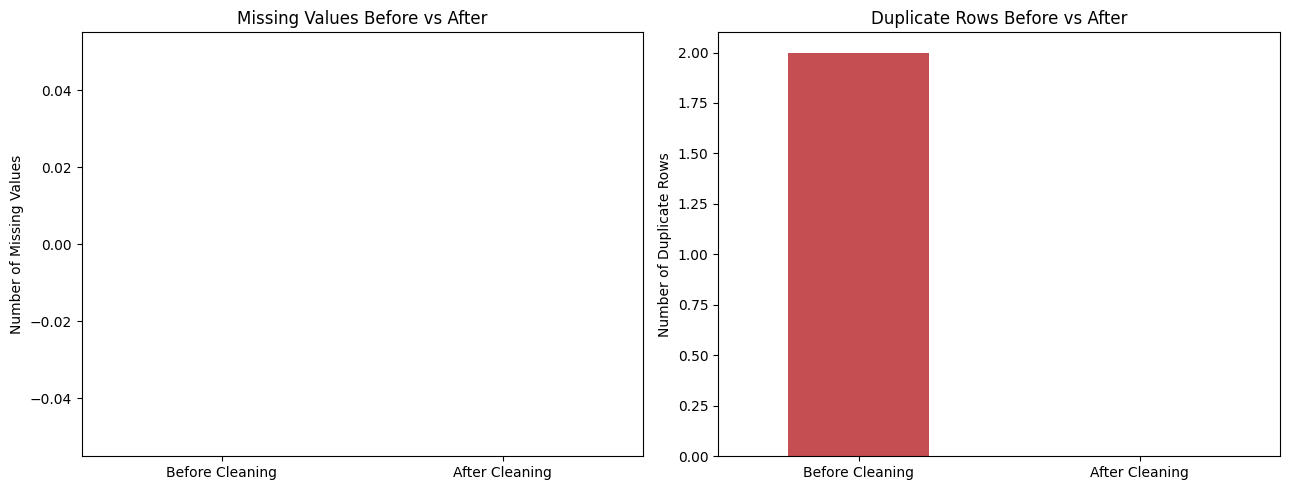

In [225]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from IPython.display import display

# ==========================================
# 1. ĐỌC DỮ LIỆU
# ==========================================

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Data/economy.csv')
df_clean = df.copy()

initial_rows = len(df_clean)

print("=" * 60)
print("             DATA CLEANING PROCESS")
print("=" * 60)
print("Dữ liệu ban đầu:", df_clean.shape)


# ==========================================
# 2. LÀM SẠCH CỘT stop
# ==========================================

stop_error_before = df_clean['stop'].astype(str).str.contains(
    r'\s$', na=False
).sum()

df_clean['stop'] = (
    df_clean['stop']
    .astype('string')
    .str.replace(r'[\r\n\t]+', ' ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

print("\n1. STOP CLEANING")
print("Số lỗi khoảng trắng ban đầu:", stop_error_before)
print("Đã chuẩn hóa cột stop.")


# ==========================================
# 3. LÀM SẠCH CỘT time_taken
# ==========================================

def convert_time(value):
    if pd.isna(value):
        return np.nan

    match = re.fullmatch(
        r'(?:(\d+)\s*h)?\s*(?:(\d+)\s*m)?',
        str(value).strip().lower()
    )

    if not match or not (match.group(1) or match.group(2)):
        return np.nan

    hours = int(match.group(1) or 0)
    minutes = int(match.group(2) or 0)

    if minutes >= 60:
        return np.nan

    total = hours * 60 + minutes

    return total if total > 0 else np.nan


time_minutes = df_clean['time_taken'].apply(convert_time)
time_error_before = time_minutes.isna().sum()

if time_minutes.notna().any():
    median_time = time_minutes.median()
    time_minutes = time_minutes.fillna(median_time)

    df_clean['time_taken'] = time_minutes.apply(
        lambda x: f"{int(x)//60}h {int(x)%60}m"
    )
else:
    print("Cảnh báo: Không có giá trị thời gian hợp lệ.")

print("\n2. TIME_TAKEN CLEANING")
print("Số lỗi định dạng:", time_error_before)
print("Đã chuẩn hóa cột time_taken.")


# ==========================================
# 4. LÀM SẠCH CỘT price
# ==========================================

price_before = df_clean['price'].copy()

df_clean['price'] = pd.to_numeric(
    price_before.astype(str).str.replace(
        ',', '', regex=False
    ).str.strip(),
    errors='coerce'
)

df_clean.loc[df_clean['price'] <= 0, 'price'] = np.nan

price_error_before = df_clean['price'].isna().sum()

if df_clean['price'].notna().any():
    df_clean['price'] = df_clean['price'].fillna(
        df_clean['price'].median()
    )

print("\n3. PRICE CLEANING")
print("Số giá trị không hợp lệ:", price_error_before)
print("Đã chuyển price sang kiểu số.")


# ==========================================
# 5. XÓA DỮ LIỆU TRÙNG LẶP
# ==========================================

duplicate_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

print("\n4. DUPLICATE CLEANING")
print("Số dòng trùng đã xóa:", duplicate_before)


# ==========================================
# 6. XỬ LÝ DỮ LIỆU THIẾU
# ==========================================

missing_before = df_clean.isna().sum().sum()

# Cột số: điền bằng trung vị
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:
    if df_clean[col].isna().any():
        median = df_clean[col].median()
        if pd.notna(median):
            df_clean[col] = df_clean[col].fillna(median)

# Cột phân loại: điền bằng giá trị phổ biến nhất
categorical_cols = df_clean.select_dtypes(
    include=['object', 'string', 'category']
).columns

for col in categorical_cols:
    if df_clean[col].isna().any():
        mode = df_clean[col].mode(dropna=True)
        if not mode.empty:
            df_clean[col] = df_clean[col].fillna(mode.iloc[0])

# Xóa dòng còn thiếu nếu không thể xử lý
df_clean = df_clean.dropna().copy()

missing_after = df_clean.isna().sum().sum()

print("\n5. MISSING VALUE CLEANING")
print("Giá trị thiếu ban đầu:", missing_before)
print("Giá trị thiếu còn lại:", missing_after)


# ==========================================
# 7. KIỂM TRA NGOẠI LỆ IQR
# ==========================================

outlier_results = []

for col in ['price']:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_results.append({
        'Column': col,
        'Lower Bound': lower,
        'Upper Bound': upper,
        'Outliers Remaining': count
    })

outlier_report = pd.DataFrame(outlier_results)


# ==========================================
# 8. BẢNG TỔNG HỢP KẾT QUẢ
# ==========================================

cleaning_report = pd.DataFrame({
    'Loại lỗi': [
        'stop - Khoảng trắng',
        'time_taken - Sai định dạng',
        'price - Giá trị không hợp lệ',
        'Dữ liệu trùng lặp',
        'Dữ liệu thiếu ban đầu',
        'Dữ liệu thiếu sau làm sạch'
    ],

    'Số lượng': [
        stop_error_before,
        time_error_before,
        price_error_before,
        duplicate_before,
        missing_before,
        missing_after
    ]
})

validation_report = pd.DataFrame({
    'Chỉ tiêu': [
        'Số dòng ban đầu',
        'Số dòng sau làm sạch',
        'Số dòng đã loại bỏ',
        'Số dòng trùng còn lại',
        'Số giá trị thiếu còn lại',
        'Số cột dữ liệu'
    ],

    'Kết quả': [
        initial_rows,
        len(df_clean),
        initial_rows - len(df_clean),
        df_clean.duplicated().sum(),
        df_clean.isna().sum().sum(),
        len(df_clean.columns)
    ]
})


# ==========================================
# 9. HIỂN THỊ KẾT QUẢ TRỰC TIẾP TRÊN COLAB
# ==========================================

print("\n" + "=" * 60)
print("              CLEANING REPORT")
print("=" * 60)

display(cleaning_report)

print("\n========== OUTLIER REPORT ==========")
display(outlier_report)

print("\n========== VALIDATION REPORT ==========")
display(validation_report)

print("\n========== DATA AFTER CLEANING ==========")
display(df_clean.head(10))

print("\n========== DATA TYPES ==========")
display(df_clean.dtypes.to_frame('Data Type'))


# ==========================================
# 10. BIỂU ĐỒ SO SÁNH TRƯỚC VÀ SAU LÀM SẠCH
# ==========================================

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ dữ liệu thiếu
missing_comparison = pd.Series({
    'Before Cleaning': missing_before,
    'After Cleaning': missing_after
})

missing_comparison.plot(
    kind='bar',
    ax=ax[0],
    color=['#C44E52', '#55A868']
)

ax[0].set_title('Missing Values Before vs After')
ax[0].set_ylabel('Number of Missing Values')
ax[0].tick_params(axis='x', rotation=0)

# Biểu đồ dữ liệu trùng
duplicate_comparison = pd.Series({
    'Before Cleaning': duplicate_before,
    'After Cleaning': df_clean.duplicated().sum()
})

duplicate_comparison.plot(
    kind='bar',
    ax=ax[1],
    color=['#C44E52', '#55A868']
)

ax[1].set_title('Duplicate Rows Before vs After')
ax[1].set_ylabel('Number of Duplicate Rows')
ax[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()




# **Giai đoạn 3: Phân tích và trực quan hóa**

◦ **Kiểm định giả thuyết:** Đối chiếu số liệu với các giả định ban đầu (ví dụ: mối liên hệ giữa nhóm tuổi và mức chi tiêu).

◦ **Trực quan hóa có mục tiêu:** Chọn đúng loại biểu đồ (Line, Bar, Scatter Plot, Heatmap tương quan,...) gắn liền với câu hỏi phân tích.

◦ **Diễn giải chuyên sâu (Deep Insight):** Mỗi hình vẽ, biểu đồ bắt buộc phải có phần phân tích số liệu kèm theo. Tránh các biểu đồ chỉ mang tính minh họa mà không đưa ra được nhận định, kết luận hay bài học rút ra.

**Giả thuyết 1: Business đắt hơn Economy**

In [226]:
# Kiểm chứng: so giá trung bình, trung vị, nhỏ nhất, lớn nhất của hai hạng
print(clean.groupby("class")["price"].describe()[["count", "mean", "50%", "min", "max"]].round(0))

             count     mean      50%      min       max
class                                                  
Business   93487.0  52540.0  53164.0  12000.0  123071.0
Economy   206666.0   6572.0   5772.0   1105.0   42349.0


***- Nhận Xét:***  Business/Economy là 7,99 lần theo trung bình và 9,21 lần theo trung vị. Có 17.555 vé Business (18,78%) rẻ hơn vé Economy đắt nhất. Giá Business thấp nhất (12.000) vẫn cao hơn trung vị Economy (5.772).

Số lượng vé Business có giá rẻ hơn vé Economy đắt nhất: 17,555


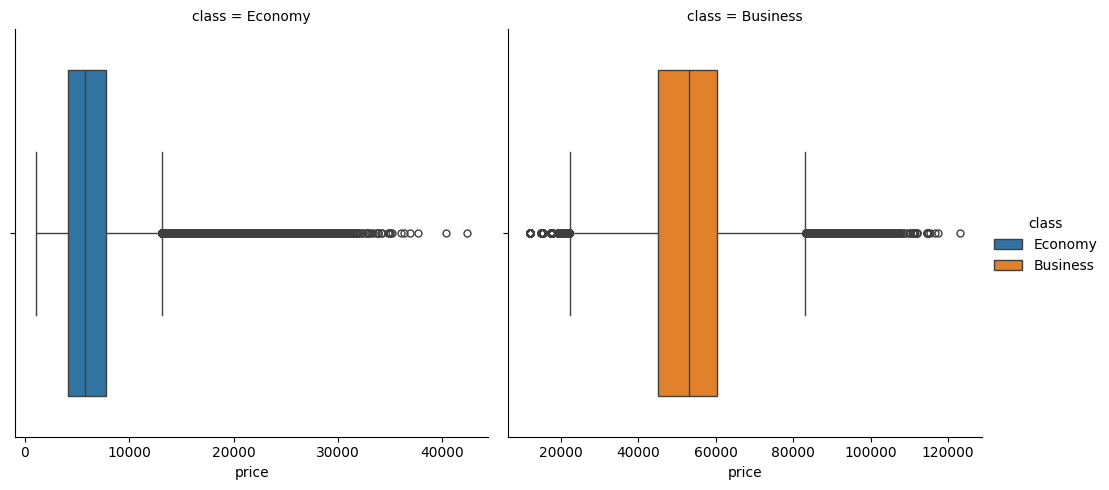

In [227]:
# Lấy giá cao nhất của hạng Economy từ bảng clean (số)
gia_max_eco = clean[clean["class"] == "Economy"]["price"].max()

# Chuyển đổi cột price của file thô 'biz' từ chuỗi có dấu phẩy sang số nguyên (int)
gia_biz_so = biz["price"].astype(str).str.replace(",", "").astype(int)

# Đếm số lượng vé Business có giá rẻ hơn vé Economy đắt nhất
n_chong = (gia_biz_so < gia_max_eco).sum()

print(f"Số lượng vé Business có giá rẻ hơn vé Economy đắt nhất: {n_chong:,}")

# Hình 3.1: Boxplot giá từng hạng, mỗi hạng một trục riêng
sns.catplot(
    data=clean,
    x="price",
    hue="class",
    col="class",
    kind="box",
    sharex=False
)
plt.show()

**Giả thuyết 2: Mua càng sát ngày bay càng đắt**

In [228]:
# Kiểm chứng: giá trung bình theo từng ngày còn lại và hạng vé
tb = clean.groupby(["class", "days_left"])["price"].mean().unstack(level=0)

# Phân nhóm days_left thành các khoảng để dễ so sàng bằng pd.cut hoặc np.where đúng chuẩn
bins = [-1, 1, 3, 7, 15, 30, 60]
labels = ["1) 1 ngày", "2) 2-3 ngày", "3) 4-7 ngày", "4) 8-15 ngày", "5) 16-30 ngày", "6) >30 ngày"]
clean["nhom_ngay"] = pd.cut(clean["days_left"], bins=bins, labels=labels)

print(clean.groupby(["nhom_ngay", "class"], observed=True)["price"].mean().unstack(level=1).round(0))

class          Business  Economy
nhom_ngay                       
1) 1 ngày       65169.0  14613.0
2) 2-3 ngày     60384.0  13562.0
3) 4-7 ngày     55062.0  10565.0
4) 8-15 ngày    52653.0   9829.0
5) 16-30 ngày   52110.0   5406.0
6) >30 ngày     51649.0   4919.0


***-Nhận xét:***
Giá trung bình Economy quanh mốc 14 đến 17 ngày: 9.364 (ngày 13), 9.455 (14), 8.379 (15), 6.338 (16), 6.170 (17). Economy mua từ 2 ngày trở xuống có giá 14.226, mua từ 16 ngày trở lên có giá 5.135, tức gấp 2,8 lần. Giá trung bình ở days_left ≥ 16 chỉ hơn ở days_left ≥ 30 là 195. Business mua 1 ngày là 65.169, cao hơn 26% so với mua 31 đến 49 ngày (51.649).

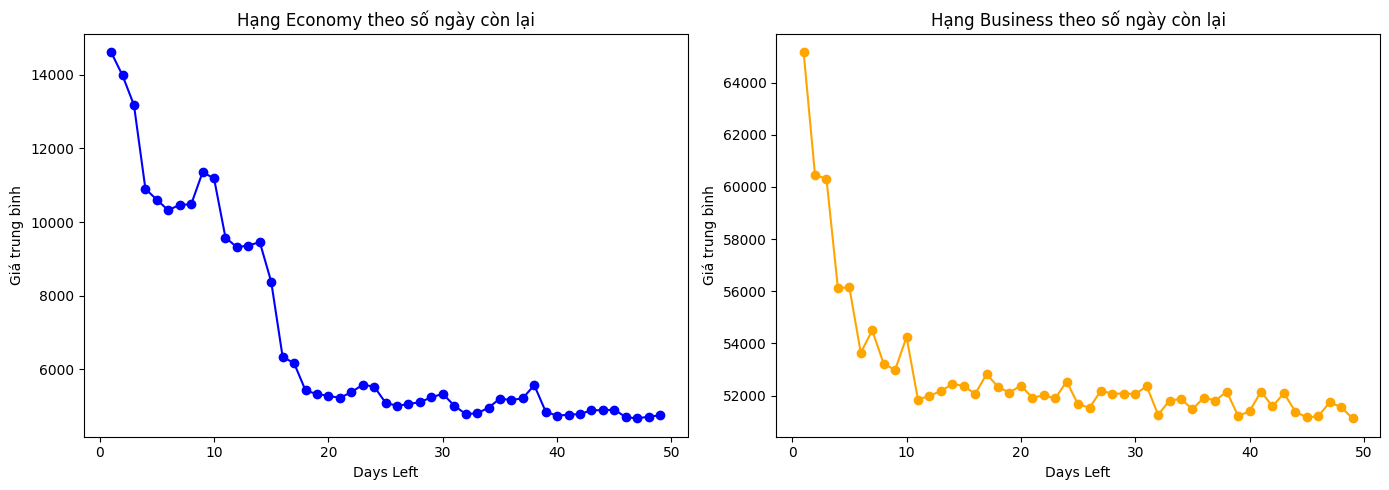

In [229]:
# Hình 3.2: đường giá trung bình theo days_left, dùng ax1 và ax2 thay cho truc[0], truc[1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

tb["Economy"].plot(ax=ax1, color="blue", marker="o")
ax1.set_title("Hạng Economy theo số ngày còn lại")
ax1.set_xlabel("Days Left")
ax1.set_ylabel("Giá trung bình")

tb["Business"].plot(ax=ax2, color="orange", marker="o")
ax2.set_title("Hạng Business theo số ngày còn lại")
ax2.set_xlabel("Days Left")
ax2.set_ylabel("Giá trung bình")

plt.tight_layout()
plt.show()

Hình 3.2. Đường Economy có một bước giảm dốc quanh ngày 15 đến 16 rồi đi ngang. Đường Business thoải hơn và chỉ cong lên ở vài ngày cuối.


**Giả thuyết 3: Giá khác nhau theo hãng và số điểm dừng**

In [230]:
# Kiểm chứng: giá trung bình theo hãng và hạng vé
print(clean.groupby(["airline", "class"])["price"].mean().unstack(level=1).round(0))

# Kiểm chứng: giá theo số điểm dừng, và crosstab đếm số vé để biết cỡ mẫu từng ô
bang_dung = clean.groupby(["stops", "class"])["price"].mean().unstack(level=1)
print(bang_dung)
print(pd.crosstab(clean["stops"], clean["class"]))

class      Business  Economy
airline                     
AirAsia         NaN   4091.0
Air_India   47131.0   7314.0
GO_FIRST        NaN   5652.0
Indigo          NaN   5324.0
SpiceJet        NaN   6179.0
Vistara     55477.0   7807.0
class            Business      Economy
stops                                 
one          54687.377156  6812.857800
two_or_more  70127.660203  9142.264279
zero         27846.339052  4012.624615
class        Business  Economy
stops                         
one             84302   166561
two_or_more      1083    12203
zero             8102    27902


In [231]:
# Kiểm chứng "có phải bay thẳng rẻ chỉ vì hãng giá rẻ bay thẳng nhiều?": so giá trong cùng một hãng
# Dùng clean thay vì eco để đồng bộ, hoặc lọc từ clean với class == 'Economy'
eco_df = clean[clean["class"] == "Economy"]

print(eco_df.groupby(["airline", "stops"])["price"].mean().unstack(level=1).round(0))

so_luong = pd.crosstab(eco_df["airline"], eco_df["stops"])
print((so_luong.div(so_luong.sum(axis="columns"), axis="index") * 100).round(1))

stops         one  two_or_more    zero
airline                               
AirAsia    4097.0       4433.0  3748.0
Air_India  7297.0      10841.0  4062.0
GO_FIRST   5972.0       7108.0  3527.0
Indigo     5733.0       7835.0  4023.0
SpiceJet   6789.0          NaN  4556.0
Vistara    7897.0      10371.0  4125.0
stops       one  two_or_more  zero
airline                           
AirAsia    70.9         14.0  15.1
Air_India  86.3          6.8   6.9
GO_FIRST   84.3          1.7  13.9
Indigo     72.3          1.7  26.0
SpiceJet   72.7          0.0  27.3
Vistara    83.9          8.3   7.8


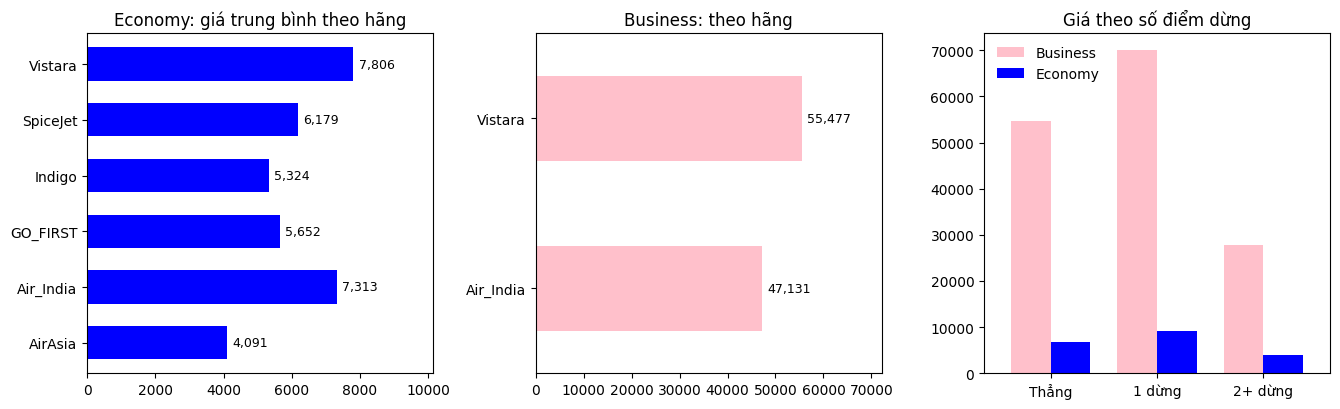

In [232]:
# Tính toán lại các biến giá trung bình theo hãng và định dạng hiển thị
gia_eco_hang = eco_df.groupby("airline")["price"].mean()
gia_biz_hang = clean[clean["class"] == "Business"].groupby("airline")["price"].mean()

def so(val):
    return f"{int(val):,}"

# Khởi tạo figure và các trục riêng biệt ax1, ax2, ax3 đúng chuẩn
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13.5, 4.2))

# 1. Biểu đồ Economy theo hãng
gia_eco_hang.plot.barh(ax=ax1, color="blue", width=0.6)
ax1.set_title("Economy: giá trung bình theo hãng")
ax1.set_ylabel("")
cao_eco = gia_eco_hang.values.max()
ax1.set_xlim(0, cao_eco * 1.3)
for i, g in enumerate(gia_eco_hang.values):
    ax1.text(g + cao_eco * 0.02, i, so(g), va="center", fontsize=9)

# 2. Biểu đồ Business theo hãng
gia_biz_hang.plot.barh(ax=ax2, color="pink", width=0.5)
ax2.set_title("Business: theo hãng")
ax2.set_ylabel("")
cao_biz = gia_biz_hang.values.max()
ax2.set_xlim(0, cao_biz * 1.3)
for i, g in enumerate(gia_biz_hang.values):
    ax2.text(g + cao_biz * 0.02, i, so(g), va="center", fontsize=9)

# 3. Biểu đồ giá theo số điểm dừng
bang_dung.plot.bar(ax=ax3, color=["pink", "blue"], width=0.75, rot=0)
ax3.set_title("Giá theo số điểm dừng")
ax3.set_xlabel("")
ax3.set_xticklabels(["Thẳng", "1 dừng", "2+ dừng"])
ax3.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.savefig("hinh_3_3_gia_theo_hang_va_diem_dung.png", dpi=300)
plt.show()

Hình 3.3. Ba khung: giá Economy theo hãng, giá Business theo hãng, và giá theo số điểm dừng (cột cam là Business, cột xanh là Economy).
